<a href="https://colab.research.google.com/github/JoshCHanson/JoshCHanson-DataScience-GenAI-Submissions/blob/main/Seminar_2/Titanic_Final_Draft.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# <u>**Seminar 2:**</u>


## <u>EXERCISE - 'titanic.csv':</u>

-  **Aim:** Investigate whether passenger class (`Pclass`) is associated with survival on the titanic.

-  **Approach:** Carry out <u>exploratory data analysis</u> (data quality checks, missing values, survival rates by class, and other candidate variables), then fit a logistic regression to model survival probability as a function of passenger class.

-  **NOTE:** Structure of the EDA follows the module material, adapted with suggestions from Claude. Furthermore, Claude helped with cleaning the messier first draft and provided explanations of the changes it used to 'tidy' the draft.

In [18]:
import numpy as np
import pandas as pd
from google.colab import files
from IPython.display import display            # Suggested for cleaner presentation by Claude.
import matplotlib.pyplot as plt
import seaborn as sns                          # After deliberation decided to use for convenience and confidence intervals.
from scipy.stats import chi2_contingency       # Claude suggested a chi-squared test.
import statsmodels.formula.api as smf


upload = files.upload()
df = pd.read_csv("titanic.csv")


def section(title):
    """Print a numbered section heading with spacing."""
    print(f"\n{'=' * 40}\n{title}\n{'=' * 40}\n")


# 1. Initial checks
section("1. Initial Checks")

print(f"Shape: {df.shape}\n")
print("Data types:")
display(df.dtypes)

print("\n")

df.info()

print("\n")

# 2. Null values
section("2. Null Values")

print("Before cleaning:")
display(df.isnull().sum())

df = df.drop(columns="Cabin")                                     # Too many missing values (687)
df["Age"] = df["Age"].fillna(df["Age"].median())                  # 177 missing
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])  # 2 missing

print("\n")

print("After cleaning:")
display(df.isnull().sum())

print("\n")

# 3. Data integrity
section("3. Data Integrity")

print(f"PassengerId unique: {df['PassengerId'].is_unique}\n")

# Values outside expected ranges
for col in ["Pclass", "Survived", "Sex"]:
    print(f"{col}:")
    display(df[col].value_counts().sort_index())
    print("\n")

print("\n")

print("Age and Fare:")
display(df[["Age", "Fare"]].describe())

print("\n")

# 4. Summary statistics
section("4. Summary of Statistics")

print("Numeric columns:")
display(df.describe(include="number"))

print("\n")

print("Categorical columns:")
display(df.describe(include="object"))

print("\n")

# 5. Target Variable Balance
section("5. Target Variable Balance")

print("Survived:")
display(df["Survived"].value_counts(normalize=True))

Saving titanic.csv to titanic (1).csv

1. Initial Checks

Shape: (891, 12)

Data types:


,0
PassengerId,int64
Survived,int64
Pclass,int64
Name,object
Sex,object
Age,float64
SibSp,int64
Parch,int64
Ticket,object
Fare,float64




<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB



2. Null Values

Before cleaning:


,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0




After cleaning:


,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0


... (10 outputs left out)



Categorical columns:


,Name,Sex,Ticket,Embarked
count,891,891,891,891
unique,891,2,681,3
top,"Braund, Mr. Owen Harris",male,347082,S
freq,1,577,7,646





5. Target Variable Balance

Survived:


,proportion
Survived,
0,0.616162
1,0.383838


### <u>**Section 5: Target Variable Balance - Summary**</u>

-  38.4% of passengers survived, so the data is imbalanced towards non-survival. Therefore, a model that always predicts "died" would score about 61.6% accuracy, which is the minimum my model needs to beat.


6. Survival by Pclass

Summary Table:


        Survival Rate  n_survived  n_passengers
Pclass                                         
1            0.629630         136           216
2            0.472826          87           184
3            0.242363         119           491




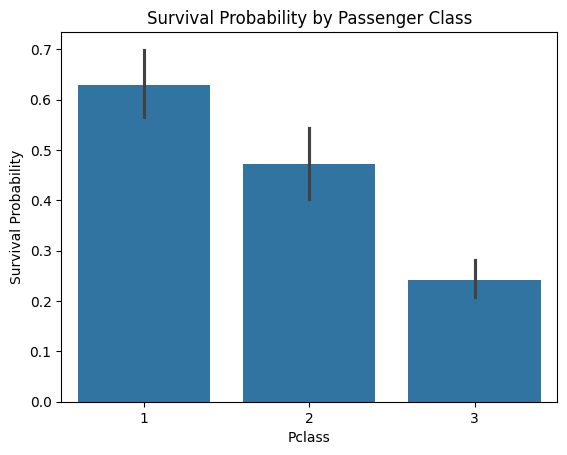



Contingency Table and chi-squared test of independence:


Survived    0    1
Pclass            
1          80  136
2          97   87
3         372  119 
chi2=102.89, p=4.549e-23


In [19]:
# 6. Survival by Pclass
section("6. Survival by Pclass")

# 6.1: Calculate Survival Rate for each class
summary = df.groupby("Pclass")["Survived"].agg(["mean", "sum", "count"]) # .agg() function allows for a survival rate for each class and a representation of sample size
summary.columns = ["Survival Rate", "n_survived", "n_passengers"]
print("Summary Table:")
print("\n")
print(summary)

print("\n")

# 6.2: Plot the graph (visualise the relationship/correlation)
sns.barplot(data=df, x="Pclass", y="Survived", errorbar =("ci", 95))     # Errorbar was a recommendation from Claude
plt.ylabel("Survival Probability")
plt.title("Survival Probability by Passenger Class")
plt.show()

print("\n")

# 6.3: Contingency Table and chi-squared test of independence
ct = pd.crosstab(df["Pclass"], df["Survived"])
chi2, p, dof, ex = chi2_contingency(ct)
print("Contingency Table and chi-squared test of independence:")
print("\n")
print(ct, f"\nchi2={chi2:.2f}, p={p:.4g}")      # The test will verify if the observed pattern hasn't happened by chance. If p < 0.05, then we have proven a high likelihood of correlation between two variables.



### <u>**Section 6: Survival by Pclass - Summary**</u>
-  **NOTE:** Used notes from a course I took on MITx platform to set up the chi-squared test of independence.

1. **Survival rates:** Survival fell with passenger class. 63.0% of 1st Class passengers survived, compared with only 24% of 3rd Class passengers.

2. **Visualisation:** The bar chart shows the same pattern clearly, with survival probability decreasing from 1st to 3rd Class.

3. **Statistical test:** The chi-square test of independence gave a p-value < 0.0001, so the association between `Pclass` and survival is very unlikely to be due to chance.


7. Candidate Second Predictors

            mean  count
Sex                    
female  0.742038    314
male    0.188908    577 



              mean  count
Embarked                 
C         0.553571    168
Q         0.389610     77
S         0.339009    646 



           mean  count
SibSp                 
0      0.345395    608
1      0.535885    209
2      0.464286     28
3      0.250000     16
4      0.166667     18
5      0.000000      5
8      0.000000      7 



           mean  count
Parch                 
0      0.343658    678
1      0.550847    118
2      0.500000     80
3      0.600000      5
4      0.000000      4
5      0.200000      5
6      0.000000      1 





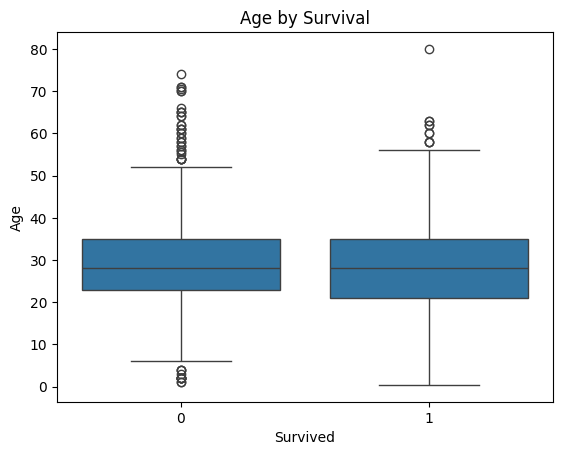

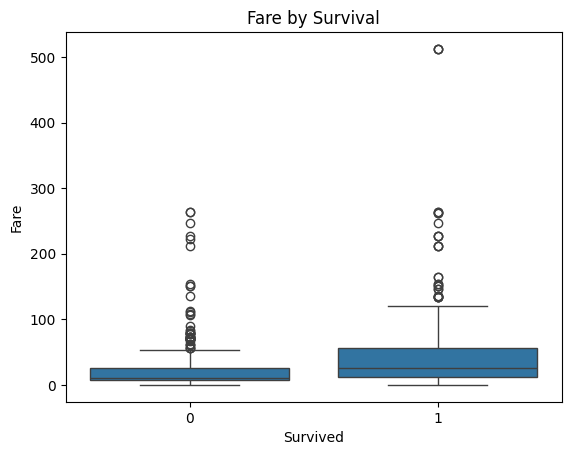



Sex within Pclass:


Sex,female,male
Pclass,,
1,0.968085,0.368852
2,0.921053,0.157407
3,0.500000,0.135447


In [20]:
# 7. Candidate Second Predictors
section("7. Candidate Second Predictors")

# Categorical candidates
for col in ["Sex", "Embarked", "SibSp", "Parch"]:
    print(df.groupby(col)["Survived"].agg(["mean", "count"]), "\n")
    print("\n")

# Numeric candidates
sns.boxplot(data=df, x="Survived", y="Age")
plt.title("Age by Survival")
plt.show()
print("\n")
sns.boxplot(data=df, x="Survived", y="Fare")
plt.title("Fare by Survival")
plt.show()

print("\n")

# After examining table related to 'Sex' vs 'Survival', it seems as if there is some form of relationship that requires further investigation:
print("Sex within Pclass:")
df.pivot_table(values="Survived", index="Pclass", columns="Sex", aggfunc="mean")


### <u>**Section 7: Candidate Second Predictors - Summary**</u>

-  **NOTE:** Used Claude to research how to set up this pivot table.
1. **Sex:** Survival differed considerably when comparing sexes (74.2% of women vs 18.9% of men), and this held within every class, so `sex` is a <u>strong predictor independent of `Pclass`</u>.
2. **Age and Fare:** `Age` showed little difference between survivors and non-survivors (note that missing age values were filled with the median), while survivors paid higher fares, though `Fare` is most likely linked to `Pclass`.
3. **Other variables:** `Embarked`, `SibSp` and `Parch` showed weaker patterns and several groups were very small, so I did not treat them as strong candidates.
4. **Decision:** I will carry Sex forward as the second predictor alongside Pclass, and check Fare's overlap with Pclass in section 8.


8. Confounding and Colinearity

Table for Relationship between Fare and Pclass:


        count       mean        std  min       25%      50%   75%       max
Pclass                                                                     
1       216.0  84.154687  78.380373  0.0  30.92395  60.2875  93.5  512.3292
2       184.0  20.662183  13.417399  0.0  13.00000  14.2500  26.0   73.5000
3       491.0  13.675550  11.778142  0.0   7.75000   8.0500  15.5   69.5500




Table for Relationship between Age and Pclass:


        count       mean        std   min    25%   50%    75%   max
Pclass                                                             
1       216.0  36.812130  14.182103  0.92  28.00  35.0  47.25  80.0
2       184.0  29.765380  13.581096  0.67  23.00  28.0  36.00  70.0
3       491.0  25.932627  10.697676  0.42  20.25  28.0  29.00  74.0




Correlations among numeric columns:




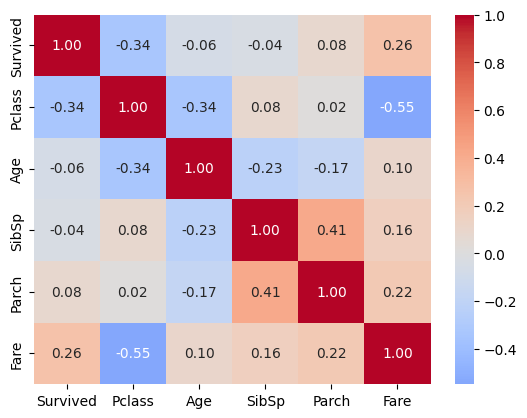

In [21]:
# 8. Confounding and Colinearity
section("8. Confounding and Colinearity")

# Fare and Pclass are closely related
print("Table for Relationship between Fare and Pclass:")
print("\n")
print(df.groupby("Pclass")["Fare"].describe())

print("\n")
print("\n")

# Age by class
print("Table for Relationship between Age and Pclass:")
print("\n")
print(df.groupby("Pclass")["Age"].describe())

print("\n")
print("\n")

# Correlations among numeric columns
print("Correlations among numeric columns:")
print("\n")
sns.heatmap(df[["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare"]].corr(),
            annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.show()

### <u>**Section 8: Confounding and Colinearity - Summary**</u>
-  **NOTE:** Claude came up with the idea for this section. I researched the way to code this and verified using Claude's code snippets.

1. **Fare and Pclass:** Median fare fell sharply from 1st to 3rd class, and the two variables are moderately correlated (-0.55), so `Fare` largely duplicates information already in `Pclass`.
2. **Correlation with survival:** `Pclass` (-0.34) and `Fare` (0.26) were the strongest numeric correlates of survival, while `Age`, `SibSp` and `Parch` were all close to zero.
3. **Age:** Passengers in higher classes tended to be older, though missing ages were filled with the median, which <u>may flatten this pattern.</u>
4. **Decision:** I will not include `Fare` alongside `Pclass`, to avoid overlapping predictors, and will use `Pclass` and `Sex` in the logistic regression.

In [23]:
# 9. Logistic Regression
section("9. Logistic Regression")

m_num = smf.logit("Survived ~ Pclass", data=df).fit()
m_cat = smf.logit("Survived ~ C(Pclass)", data=df).fit()
print(m_num.aic, m_cat.aic)
print("\n")
print(m_num.summary())


9. Logistic Regression

Optimization terminated successfully.
         Current function value: 0.608531
         Iterations 5
Optimization terminated successfully.
         Current function value: 0.607805
         Iterations 5
1088.4015699675617 1089.108012530539


                           Logit Regression Results                           
Dep. Variable:               Survived   No. Observations:                  891
Model:                          Logit   Df Residuals:                      889
Method:                           MLE   Df Model:                            1
Date:                Fri, 13 Nov 2026   Pseudo R-squ.:                 0.08617
Time:                        03:17:47   Log-Likelihood:                -542.20
converged:                       True   LL-Null:                       -593.33
Covariance Type:            nonrobust   LLR p-value:                 4.885e-24
                 coef    std err          z      P>|z|      [0.025      0.975]
---------------------

## <u>**Overall Summary:**</u>

-  **NOTE:** This summary was redrafted through Claude.

-  **Model choice:** `Pclass` as a numeric predictor (AIC 1088.4) was preferred over `Pclass` as a categorical variable (AIC 1089.1). The difference is too small to justify the extra parameters, so I kept the simpler model.

-  **Result:** Passenger class was strongly and significantly associated with survival (coefficient = -0.850, 95% CI -1.021 to -0.679, p < 0.001). Each step down in class (1st to 2nd to 3rd) multiplies the odds of survival by about 0.43 (95% CI roughly 0.36 to 0.51), i.e. a reduction of around 57%.

-  **Caveat:** <u>This is an association, not causation.</u> Class is also linked to other factors such as sex and cabin location. The model explains only a modest share of the variation (pseudo R² = 0.086).